# TP Integrador · Segundo Parcial — Python para Ciencia de Datos (UADE)

**Dataset:** [Student Sleep, Screen Time & Academic Performance](https://www.kaggle.com/datasets/aamir28/student-sleep-screen-time-and-academic-performance) (Kaggle)

**Pregunta que queremos responder con un modelo:**
¿Podemos predecir el **rendimiento académico (`cgpa`)** de un/a estudiante a partir de sus hábitos de sueño, su uso de pantallas y otras variables de estilo de vida (estudio semanal, asistencia, cafeína, ejercicio, etc.)? Es un problema de **regresión** (`cgpa` es una variable numérica continua entre 0 y 4).

**Integrantes:** _completar con los nombres del grupo_

**Estado de este notebook:** las secciones 1 a 3 (carga y calidad, EDA univariado, EDA bivariado) están resueltas. Las secciones 4 a 6 (agregaciones, modelo y conclusiones) quedan para el resto del equipo — ver los encabezados "pendiente" al final.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)
%matplotlib inline

Definimos acá un par de funciones chiquitas que vamos a reutilizar varias veces en el notebook (histograma con media/mediana marcadas, límites de Tukey para outliers e interpretación de un coeficiente de correlación), para no repetir el mismo código en cada celda.

In [2]:
def plot_histograma_full(df, variable, desvio=False, bins="auto"):
    """Histograma con KDE, marcando media y mediana (y +-1 desvío si desvio=True)."""
    sns.histplot(data=df, x=variable, bins=bins, kde=True)

    media = df[variable].mean()
    mediana = df[variable].median()
    std = df[variable].std()

    plt.axvline(media, linestyle="-", color="red", label=f"Media: {media:.2f}")
    plt.axvline(mediana, linestyle="--", color="orange", label=f"Mediana: {mediana:.2f}")

    if desvio:
        plt.axvline(media + std, linestyle="--", color="green", label=f"+1std: {media + std:.2f}")
        plt.axvline(media - std, linestyle="--", color="green", label=f"-1std: {media - std:.2f}")

    plt.title(f"Distribución de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.legend()


def limites_tukey(serie):
    """Devuelve (limite_inferior, limite_superior) según el criterio de Tukey (1.5 x RIC)."""
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    RIC = Q3 - Q1
    return Q1 - 1.5 * RIC, Q3 + 1.5 * RIC


def detectar_outliers_tukey(df, columna):
    """Devuelve el sub-DataFrame de outliers de `columna` según el criterio de Tukey."""
    limite_inf, limite_sup = limites_tukey(df[columna])
    return df[(df[columna] < limite_inf) | (df[columna] > limite_sup)]


def interpretar_correlacion(valor):
    """Clasifica un coeficiente de Pearson según su magnitud."""
    v = abs(valor)
    if v <= 0.25:
        return "No hay relación lineal"
    elif v <= 0.50:
        return "Relación lineal débil"
    elif v <= 0.75:
        return "Relación lineal moderada"
    else:
        return "Relación lineal fuerte"

## 1. Carga y calidad de los datos

### 1.1 Carga del dataset

In [3]:
df = pd.read_csv("data/student_sleep_screen_time_academic_performance.csv")
print(f"Filas: {df.shape[0]} — Columnas: {df.shape[1]}")
df.head()

Filas: 500 — Columnas: 25


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.30,7.60,2.00,...,0,10.00,7,5.00,7.00,15.60,80.00,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.10,5.90,2.70,...,3,7.00,3,6.00,7.00,17.50,78.90,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.40,8.40,1.80,...,1,9.00,2,5.00,1.00,19.00,69.70,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.90,5.10,2.40,...,3,6.00,4,3.00,7.00,7.30,59.10,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.40,5.90,2.00,...,2,7.00,6,8.00,3.00,23.60,79.90,No,Summer,2.74


### 1.2 Diccionario de columnas

| Columna | Tipo | Descripción |
|---|---|---|
| `student_id` | texto | Identificador único del/la estudiante (ej. `STU2001`) |
| `age` | numérica | Edad en años |
| `gender` | categórica | Género autopercibido |
| `year_of_study` | numérica | Año de la carrera que está cursando (1 a 5) |
| `major_category` | categórica | Área de estudio (STEM, Humanities, Business, etc.) |
| `residence_type` | categórica | Tipo de residencia (con familia, dormitorio, depto, homestay) |
| `chronotype` | categórica | Cronotipo de sueño (madrugador, intermedio, nocturno) |
| `avg_bedtime_hour` | numérica | Hora promedio a la que se acuesta, en escala 0-24 (variable circular) |
| `avg_sleep_hours_weekday` | numérica | Horas promedio de sueño en días de semana |
| `weekend_sleep_delta_hours` | numérica | Diferencia de horas de sueño el fin de semana vs. entre semana (puede ser negativa) |
| `pre_sleep_screen_time_min` | numérica | Minutos de uso de pantalla justo antes de dormir |
| `daily_screen_time_hours` | numérica | Horas totales de uso de pantalla por día |
| `primary_device` | categórica | Dispositivo principal que usa (smartphone, laptop, tablet) |
| `device_free_before_bed` | categórica | Si evita pantallas antes de dormir (Sí/No) |
| `caffeine_drinks_per_day` | numérica | Cantidad de bebidas con cafeína por día |
| `naps_per_week` | numérica | Cantidad de siestas por semana |
| `sleep_quality_score` | numérica | Calidad de sueño autopercibida, escala 1-10 |
| `exercise_days_per_week` | numérica | Días de ejercicio por semana (0-7) |
| `energy_level` | numérica | Nivel de energía autopercibido, escala 1-10 |
| `concentration_difficulty` | numérica | Dificultad de concentración autopercibida, escala 1-10 |
| `weekly_study_hours` | numérica | Horas de estudio por semana |
| `class_attendance_percent` | numérica | Porcentaje de asistencia a clases |
| `has_part_time_job` | categórica | Si tiene trabajo part-time (Sí/No) |
| `semester_type` | categórica | Tipo de semestre (Fall, Spring, Summer) |
| `cgpa` | numérica | Promedio académico acumulado, escala 0-4 — 🎯 **variable que queremos predecir** |

No hay columnas de fecha; el dataset mezcla variables numéricas y categóricas, tal como pide la consigna.

### 1.3 Tipos de datos

Miramos qué tipo le asignó pandas a cada columna, para detectar si alguna numérica quedó como texto (o viceversa) antes de seguir.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    object 
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    object 
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    object 
 5   residence_type             500 non-null    object 
 6   chronotype                 500 non-null    object 
 7   avg_bedtime_hour           500 non-null    float64
 8   avg_sleep_hours_weekday    500 non-null    float64
 9   weekend_sleep_delta_hours  500 non-null    float64
 10  pre_sleep_screen_time_min  500 non-null    int64  
 11  daily_screen_time_hours    500 non-null    float64
 12  primary_device             500 non-null    object 
 13  device_free_before_bed     491 non-null    object 

Las 25 columnas se leyeron con el tipo esperado: `student_id` y las categóricas (`gender`, `major_category`, `residence_type`, `chronotype`, `primary_device`, `device_free_before_bed`, `has_part_time_job`, `semester_type`) como `object`, y el resto como `int64`/`float64`. El dataset no tiene columnas de fecha.

No hay que convertir ningún tipo acá; el único trabajo pendiente es de **limpieza de contenido** (nulos, duplicados y valores imposibles), que vemos a continuación.

### 1.4 Valores nulos

In [5]:
nulos = df.isna().sum()
nulos_pct = (nulos / len(df) * 100).round(2)
pd.DataFrame({"nulos": nulos, "% nulos": nulos_pct})[nulos > 0].sort_values("% nulos", ascending=False)

,nulos,% nulos
energy_level,15,3.00
concentration_difficulty,14,2.80
device_free_before_bed,9,1.80
cgpa,7,1.40
sleep_quality_score,6,1.20


Encontramos nulos en 5 columnas, todas con una proporción baja (entre el 1.2% y el 3%):

| Columna | % nulos | Decisión | Por qué |
|---|---|---|---|
| `cgpa` | 1.40% | **Eliminar esas filas** | Es la variable que queremos predecir (`y`). Imputar el target inventaría la respuesta que el modelo tiene que aprender a predecir, así que no sirve para entrenar ni para evaluar. |
| `energy_level` | 3.00% | Imputar con la **mediana** | Es una escala ordinal 1-10; la mediana no se deja arrastrar por outliers y mantiene la escala original. |
| `concentration_difficulty` | 2.80% | Imputar con la **mediana** | Mismo criterio: escala ordinal 1-10. |
| `sleep_quality_score` | 1.20% | Imputar con la **mediana** | Mismo criterio: escala ordinal 1-10. |
| `device_free_before_bed` | 1.80% | Imputar con la **moda** | Es categórica binaria (Sí/No); la moda es la forma estándar de imputar una categórica con pocos nulos. |

En los tres casos de columnas numéricas usamos mediana en vez de media para no distorsionar la escala con valores extremos. Ninguna columna tiene tantos nulos como para justificar eliminarla por completo.

In [6]:
df_clean = df.copy()

# El target no se imputa: sin cgpa no podemos entrenar ni evaluar el modelo.
df_clean = df_clean.dropna(subset=["cgpa"])

for col in ["sleep_quality_score", "energy_level", "concentration_difficulty"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

df_clean["device_free_before_bed"] = df_clean["device_free_before_bed"].fillna(
    df_clean["device_free_before_bed"].mode()[0]
)

print(f"Filas antes: {len(df)} — Filas después de sacar nulos de cgpa: {len(df_clean)}")
print(f"Nulos restantes: {df_clean.isna().sum().sum()}")

Filas antes: 500 — Filas después de sacar nulos de cgpa: 493
Nulos restantes: 0


### 1.5 Duplicados

In [7]:
print(f"Filas duplicadas (todas las columnas): {df_clean.duplicated().sum()}")
print(f"student_id duplicados: {df_clean['student_id'].duplicated().sum()}")
print(f"student_id únicos: {df_clean['student_id'].nunique()} de {len(df_clean)} filas")

Filas duplicadas (todas las columnas): 0
student_id duplicados: 0
student_id únicos: 493 de 493 filas


No hay filas duplicadas ni `student_id` repetidos: cada fila representa a un/a estudiante distinto/a. No hace falta deduplicar.

### 1.6 Valores imposibles e inconsistencias

In [1]:
df_clean.describe()

NameError: name 'df_clean' is not defined

Revisando los rangos de `describe()` y los valores de las columnas categóricas aparecen tres problemas:

In [9]:
for col in df_clean.select_dtypes(include="object").columns:
    if col != "student_id":
        print(f"{col}: {sorted(df_clean[col].unique())}")

gender: ['F', 'Female', 'M', 'Male', 'Non-binary', 'Prefer not to say', 'female', 'male']
major_category: ['Arts', 'Business', 'Health Sciences', 'Humanities', 'Law', 'STEM', 'Social Sciences']
residence_type: ['Dormitory', 'Homestay', 'Off-campus Apartment', 'With Family']
chronotype: ['Early Bird', 'Intermediate', 'Night Owl']
primary_device: ['Laptop', 'Smartphone', 'Tablet']
device_free_before_bed: ['No', 'Yes']
has_part_time_job: ['No', 'Yes']
semester_type: ['Fall', 'Spring', 'Summer']


**Problema 1 — `gender` con la misma categoría escrita de formas distintas.** `"Male"`/`"male"`/`"M"` son el mismo valor, igual que `"Female"`/`"female"`/`"F"`. `"Non-binary"` y `"Prefer not to say"` sí son categorías genuinas y las dejamos como están.

**Decisión:** normalizar a `Male` / `Female`, dejando el resto intacto.

In [10]:
mapa_gender = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
df_clean["gender"] = (
    df_clean["gender"].str.strip().str.lower().replace(mapa_gender).str.title()
)
# str.title() deja "Non-binary" -> "Non-Binary" y "Prefer not to say" -> "Prefer Not To Say";
# lo corregimos a mano para no perder la capitalización original de esas dos categorías.
df_clean["gender"] = df_clean["gender"].replace(
    {"Non-Binary": "Non-binary", "Prefer Not To Say": "Prefer not to say"}
)
df_clean["gender"].value_counts()

gender
Female               239
Male                 230
Prefer not to say     12
Non-binary            12
Name: count, dtype: int64

**Problema 2 — outliers extremos en variables de tiempo.** Con el criterio de Tukey (1.5 × RIC) aparecen algunos valores que se alejan mucho del resto:

In [11]:
for col in ["weekly_study_hours", "pre_sleep_screen_time_min"]:
    li, ls = limites_tukey(df_clean[col])
    outliers = detectar_outliers_tukey(df_clean, col)
    print(f"{col}: límites normales=({li:.1f}, {ls:.1f}) -> {len(outliers)} outlier(s)")
    print(sorted(outliers[col].tolist()))
    print()

weekly_study_hours: límites normales=(-0.1, 32.7) -> 3 outlier(s)
[33.8, 39.1, 88.5]

pre_sleep_screen_time_min: límites normales=(-26.0, 102.0) -> 3 outlier(s)
[103, 121, 240]



El caso más extremo es un/a estudiante con `weekly_study_hours = 88.5`: serían más de 12 horas de estudio **todos los días de la semana sin excepción**, muy por encima de cualquier otro caso del dataset (el segundo valor más alto es 39.1). Es un valor físicamente posible pero extremadamente improbable, y a la vez no hay forma de confirmar si es un dato real o un error de tipeo (por ejemplo, podría ser horas *mensuales* y no semanales).

Los outliers de `pre_sleep_screen_time_min` (hasta 240 minutos = 4 horas de pantalla antes de dormir) sí son físicamente plausibles para alguien con insomnio o uso compulsivo del celular, así que no los tocamos.

**Decisión:** en vez de eliminar la fila de `weekly_study_hours` (perderíamos toda la información del resto de sus columnas), la *acotamos* (winsorizing) al límite superior de Tukey. Así el valor deja de dominar las estadísticas y los gráficos, pero la fila se conserva para el resto del análisis.

In [12]:
li, ls = limites_tukey(df_clean["weekly_study_hours"])
n_afectados = (df_clean["weekly_study_hours"] > ls).sum()
df_clean["weekly_study_hours"] = df_clean["weekly_study_hours"].clip(upper=ls)
print(f"{n_afectados} valor(es) acotado(s) a {ls:.1f} horas semanales")

3 valor(es) acotado(s) a 32.7 horas semanales


**Problema 3 — `avg_bedtime_hour` es una variable circular.** Está expresada como hora del día en formato 0-24 (ej. `23.8` ≈ 23:48, `0.1` ≈ 00:06), así que un valor de `0.1` y uno de `23.9` representan horarios casi idénticos (minutos antes/después de la medianoche) pero están en extremos opuestos de la escala numérica. No es un valor imposible, pero **no se puede tratar como una variable lineal común** (por ejemplo, un promedio simple entre `0.1` y `23.9` da ≈12, que sería mediodía, totalmente al revés de la realidad).

**Decisión:** no la transformamos en esta etapa, pero lo dejamos documentado para que, si se usa como predictora, se recodifique antes como "horas desde las 21:00" o con una transformación circular (seno/coseno), y no se la use ni se la promedie tal cual viene.

Por último, confirmamos que las columnas restantes no tienen valores fuera de rango esperable (edad 17-27, año de cursada 1-5, porcentaje de asistencia entre 0 y 100, `cgpa` entre 0 y 4, etc.):

In [13]:
rangos_esperados = {
    "age": (16, 35),
    "year_of_study": (1, 6),
    "class_attendance_percent": (0, 100),
    "cgpa": (0, 4),
    "avg_sleep_hours_weekday": (0, 24),
}

for col, (lo, hi) in rangos_esperados.items():
    fuera_de_rango = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    print(f"{col}: {fuera_de_rango} valor(es) fuera de [{lo}, {hi}]")

age: 0 valor(es) fuera de [16, 35]
year_of_study: 0 valor(es) fuera de [1, 6]
class_attendance_percent: 0 valor(es) fuera de [0, 100]
cgpa: 0 valor(es) fuera de [0, 4]
avg_sleep_hours_weekday: 0 valor(es) fuera de [0, 24]


No aparece ningún valor fuera de rango en estas columnas: la calidad del dataset, una vez corregidos `gender`, los nulos y el outlier de `weekly_study_hours`, es buena.

### 1.7 🔑 Resumen de calidad de datos

| Problema encontrado | Columna(s) | Decisión tomada | Por qué |
|---|---|---|---|
| Nulos en el target | `cgpa` (1.4%) | Eliminar filas | No se puede entrenar/evaluar sin la respuesta real |
| Nulos en numéricas ordinales | `sleep_quality_score`, `energy_level`, `concentration_difficulty` | Imputar con mediana | Robusta a outliers, preserva la escala 1-10 |
| Nulos en categórica binaria | `device_free_before_bed` | Imputar con moda | Estándar para categóricas con pocos nulos |
| Categorías repetidas por formato | `gender` | Normalizar texto (`Male`/`Female`) | `"M"`, `"male"`, `"Male"` son la misma categoría |
| Outlier extremo | `weekly_study_hours` | Acotar (winsorize) al límite de Tukey | Valor físicamente posible pero muy improbable; se conserva la fila |
| Variable circular | `avg_bedtime_hour` | Sin cambios, documentado | No es apta para promediar/escalar como variable lineal sin recodificar |
| Duplicados | — | Ninguno encontrado | Verificado por fila completa y por `student_id` |

A partir de acá trabajamos siempre con `df_clean`.

## 2. EDA univariado

Nos vamos a enfocar en la variable que queremos predecir (`cgpa`) y en las variables de estilo de vida que más se relacionan conceptualmente con el sueño, las pantallas y el estudio.

### 2.1 Estadística descriptiva — variables numéricas

In [14]:
variables_numericas = [
    "cgpa", "avg_sleep_hours_weekday", "weekend_sleep_delta_hours",
    "daily_screen_time_hours", "pre_sleep_screen_time_min",
    "weekly_study_hours", "class_attendance_percent",
    "sleep_quality_score", "energy_level", "concentration_difficulty",
]
df_clean[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
cgpa,493.00,2.83,0.33,1.89,2.62,2.85,3.05,3.95
avg_sleep_hours_weekday,493.00,6.61,1.44,1.50,5.70,6.60,7.70,10.50
weekend_sleep_delta_hours,493.00,1.53,0.96,-1.00,0.90,1.50,2.20,4.40
daily_screen_time_hours,493.00,5.83,2.05,0.50,4.50,5.80,7.20,19.50
pre_sleep_screen_time_min,493.00,38.44,23.66,0.00,22.00,36.00,54.00,240.00
weekly_study_hours,493.00,16.48,6.11,0.00,12.20,16.40,20.40,32.70
class_attendance_percent,493.00,79.39,11.86,36.90,70.90,79.80,88.00,100.00
sleep_quality_score,493.00,7.26,2.12,1.00,6.00,7.00,9.00,10.00
energy_level,493.00,5.77,1.95,1.00,5.00,6.00,7.00,10.00
concentration_difficulty,493.00,5.17,2.01,1.00,4.00,5.00,7.00,10.00


`cgpa` tiene media 2.83 y mediana 2.85 (muy parecidas, distribución simétrica), con un desvío de 0.33 — la mayoría de los/las estudiantes están entre 2.5 y 3.2. En promedio duermen 6.6 horas los días de semana (bastante por debajo de las 8 horas recomendadas) y usan la pantalla 5.8 horas diarias, de las cuales ~38 minutos son justo antes de dormir.

### 2.2 Estadística descriptiva — variables categóricas

In [15]:
variables_categoricas = [
    "gender", "major_category", "residence_type", "chronotype",
    "primary_device", "device_free_before_bed", "has_part_time_job", "semester_type",
]
for col in variables_categoricas:
    print(df_clean[col].value_counts(normalize=True).round(3) * 100, "\n")

gender
Female              48.50
Male                46.70
Prefer not to say    2.40
Non-binary           2.40
Name: proportion, dtype: float64 

major_category
STEM              32.50
Business          18.10
Social Sciences   15.40
Health Sciences   12.40
Humanities        10.50
Arts               6.50
Law                4.70
Name: proportion, dtype: float64 

residence_type
Dormitory              38.10
Off-campus Apartment   30.20
With Family            26.80
Homestay                4.90
Name: proportion, dtype: float64 

chronotype
Intermediate   40.40
Early Bird     30.20
Night Owl      29.40
Name: proportion, dtype: float64 

primary_device
Smartphone   54.40
Laptop       39.40
Tablet        6.30
Name: proportion, dtype: float64 

device_free_before_bed
No    75.10
Yes   24.90
Name: proportion, dtype: float64 

has_part_time_job
No    66.70
Yes   33.30
Name: proportion, dtype: float64 

semester_type
Fall     45.20
Spring   40.40
Summer   14.40
Name: proportion, dtype: float64 



La muestra está bastante balanceada entre `Male` y `Female` (~45% y ~47%), con un 5% `Non-binary` y 3% `Prefer not to say`. La carrera más representada es `STEM`, la mayoría vive `With Family` o en `Dormitory`, y cerca del 30% tiene un trabajo part-time.

### 2.3 Histogramas y boxplots — variables numéricas principales

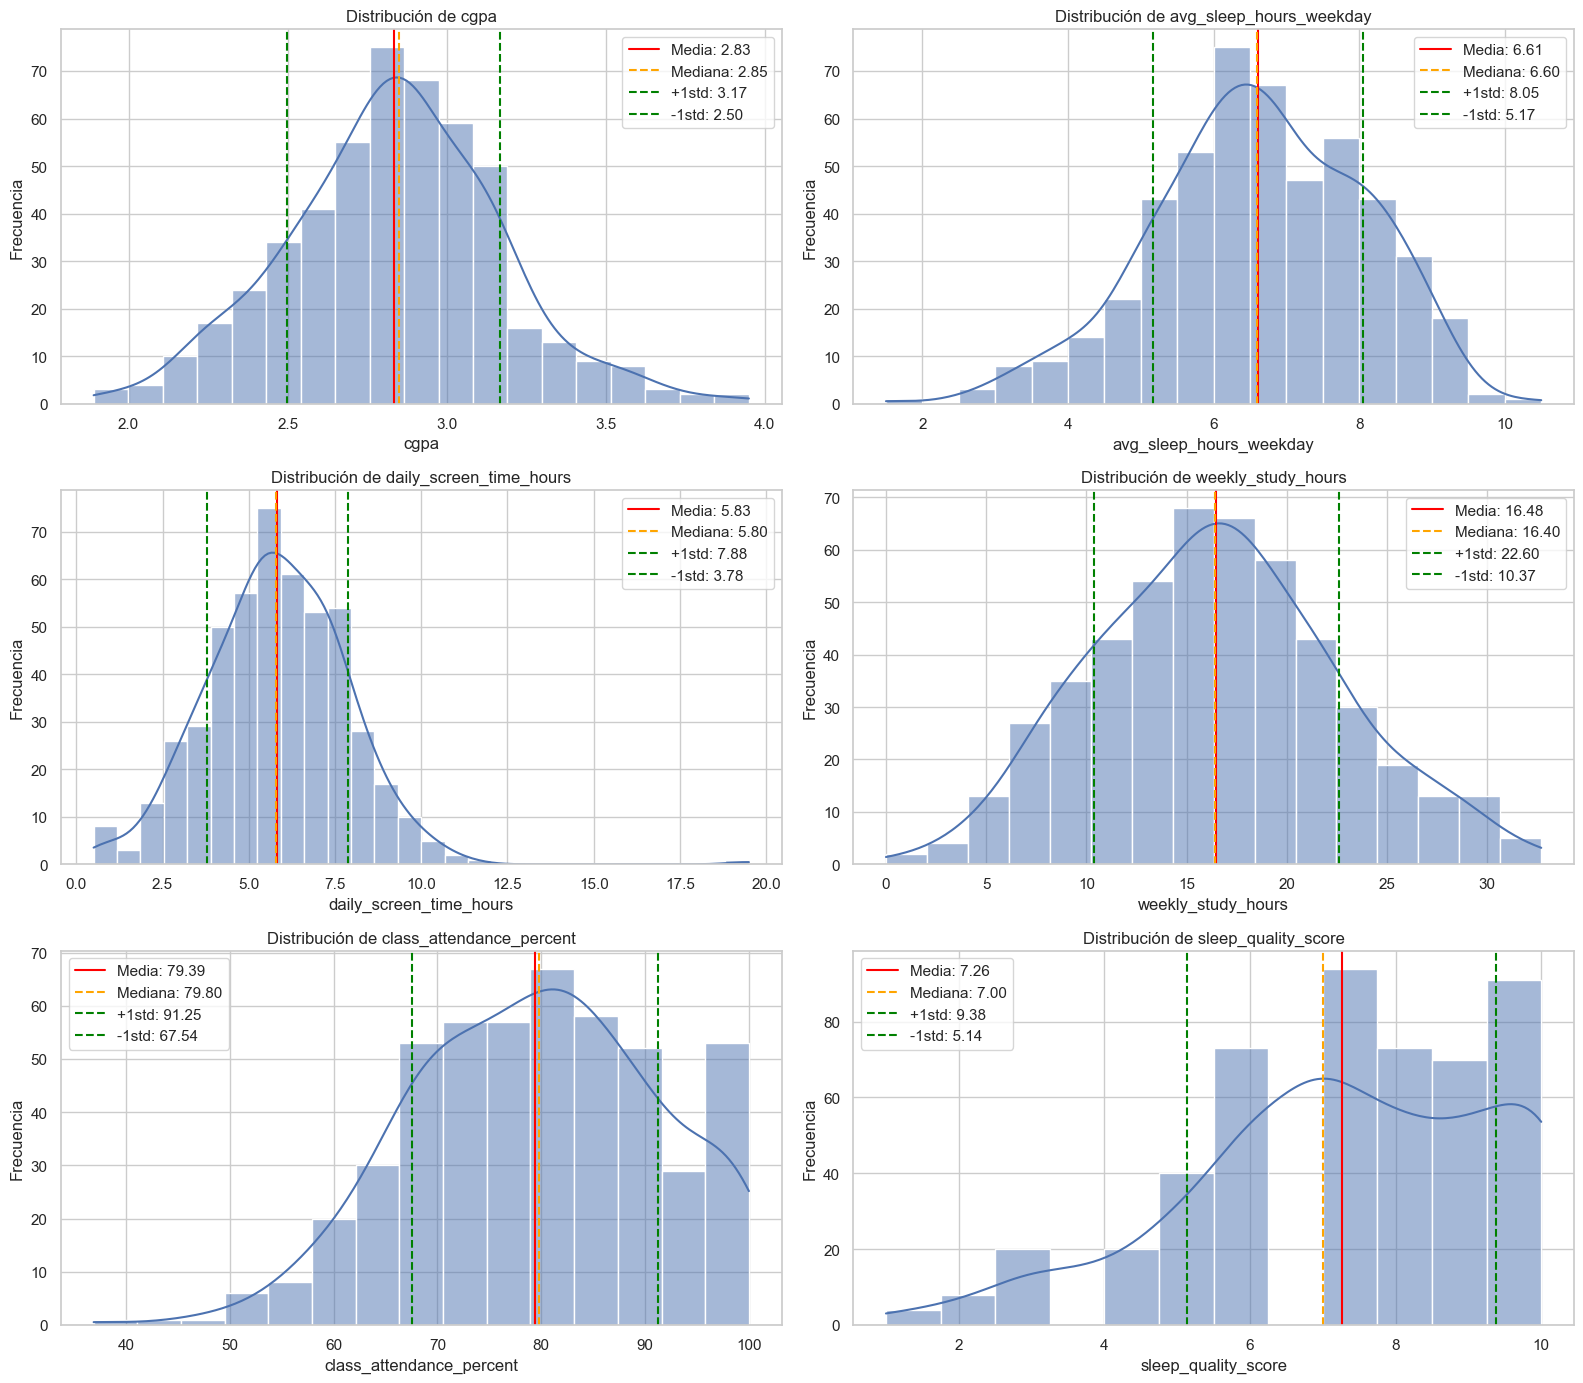

In [16]:
variables_principales = [
    "cgpa", "avg_sleep_hours_weekday", "daily_screen_time_hours",
    "weekly_study_hours", "class_attendance_percent", "sleep_quality_score",
]

plt.figure(figsize=(16, 14))
for i, col in enumerate(variables_principales, start=1):
    plt.subplot(3, 2, i)
    plot_histograma_full(df_clean, col, desvio=True)
plt.tight_layout()
plt.show()

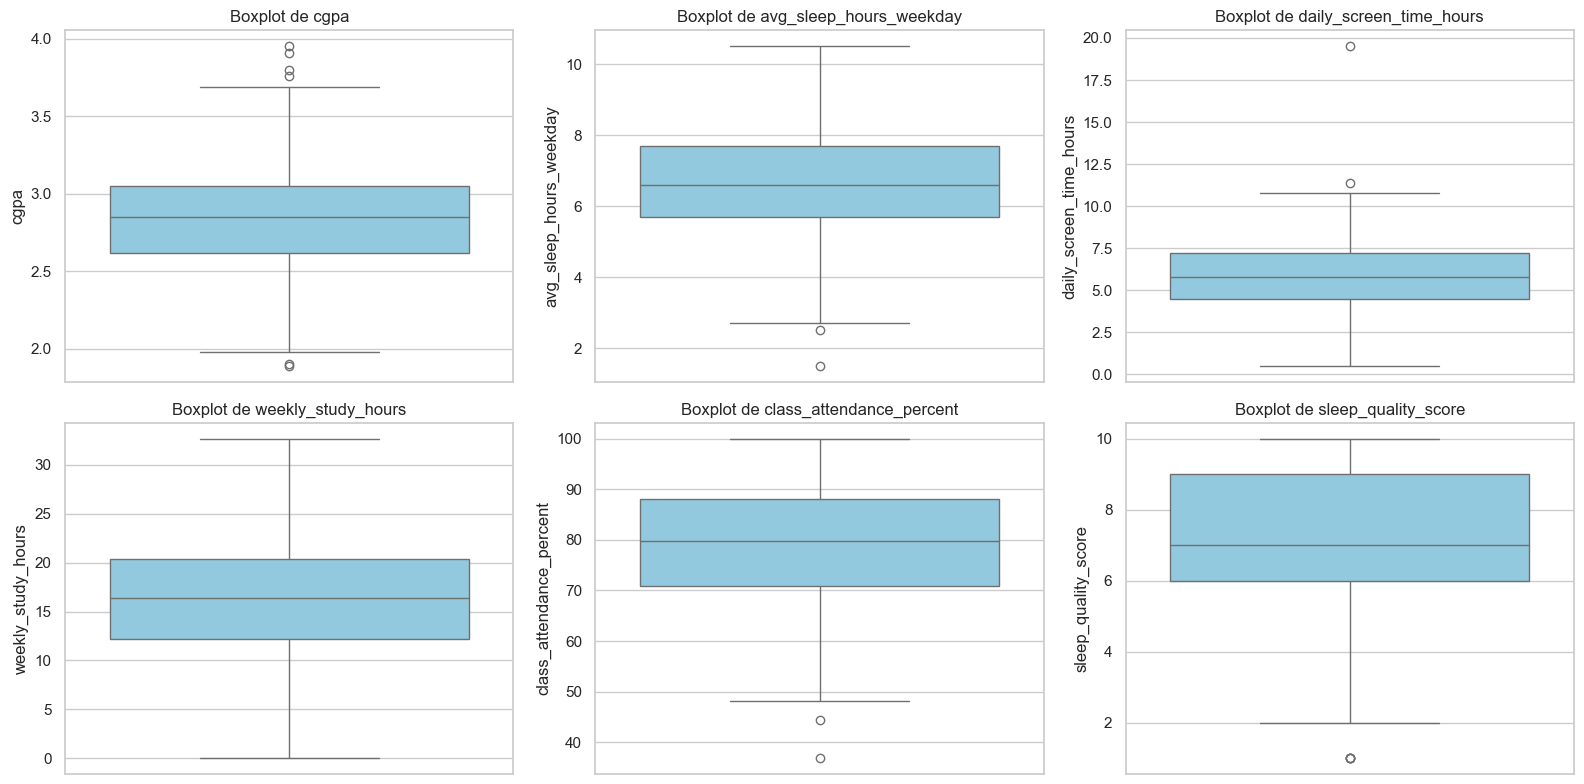

In [17]:
plt.figure(figsize=(16, 8))
for i, col in enumerate(variables_principales, start=1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[col], color="skyblue")
    plt.title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

`cgpa`, `avg_sleep_hours_weekday` y `class_attendance_percent` tienen forma aproximadamente simétrica (campana), sin outliers marcados en el boxplot. `daily_screen_time_hours` y `weekly_study_hours` están un poco sesgadas a la derecha (cola de estudiantes con valores altos), coherente con lo que vimos en la sección de calidad — recordemos que ya acotamos el caso más extremo de `weekly_study_hours`. `sleep_quality_score`, al ser una escala ordinal 1-10, se ve más "escalonada" que continua, como es de esperar.

### 2.4 Variables categóricas — countplots

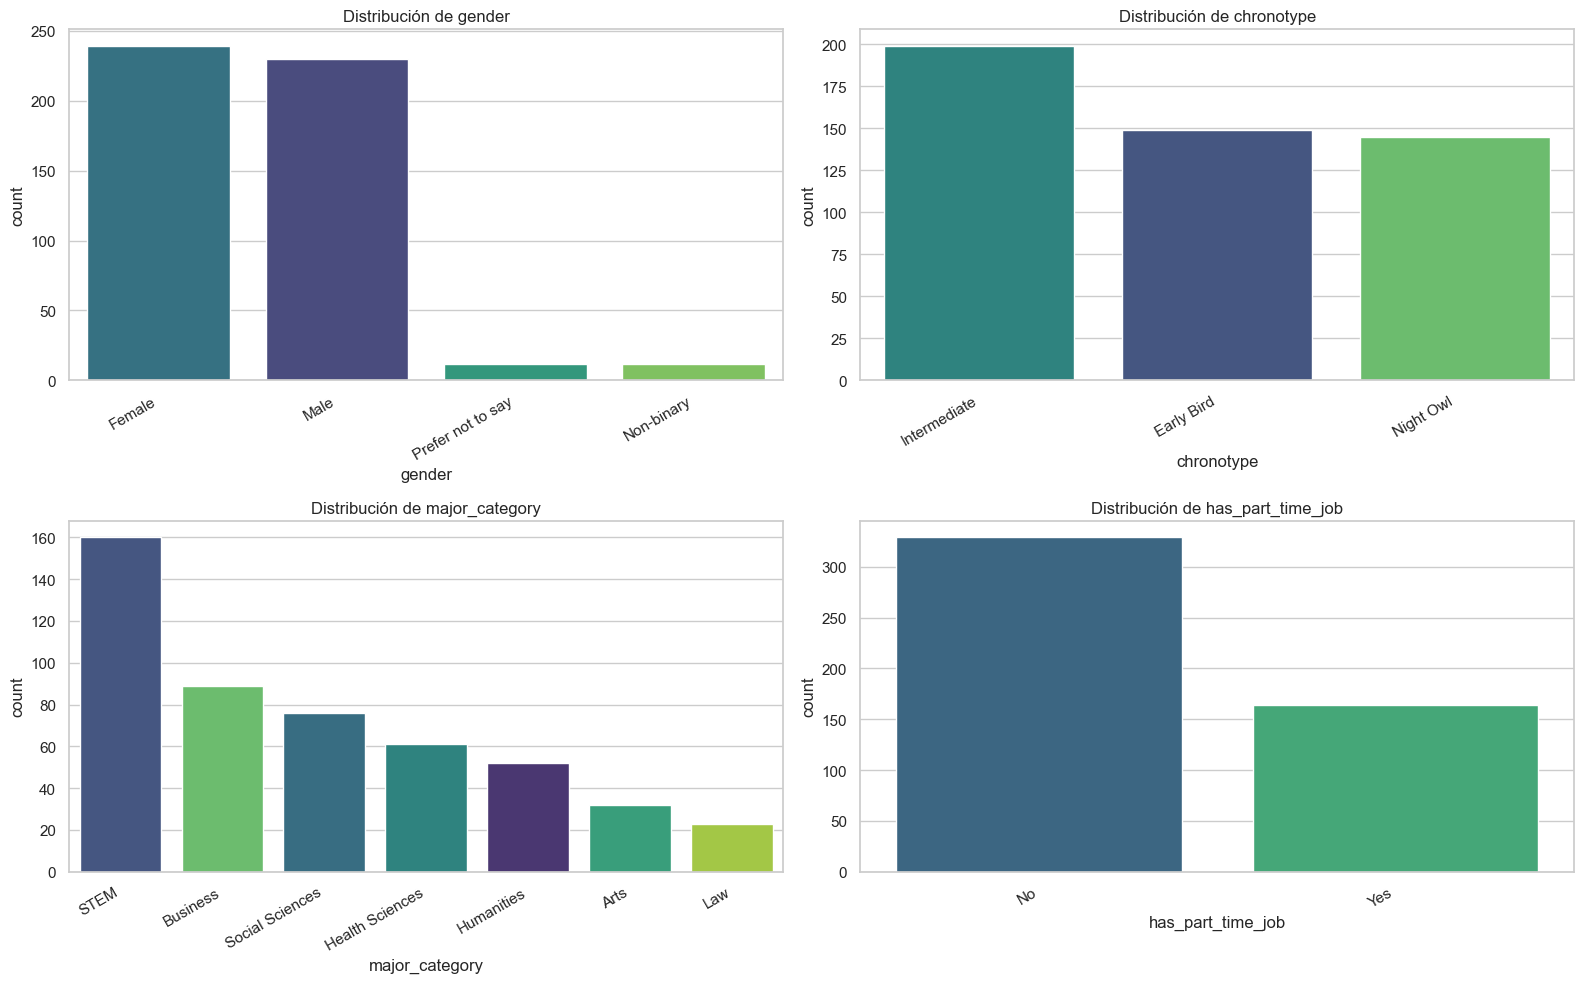

In [18]:
variables_cat_principales = ["gender", "chronotype", "major_category", "has_part_time_job"]

plt.figure(figsize=(16, 10))
for i, col in enumerate(variables_cat_principales, start=1):
    plt.subplot(2, 2, i)
    orden = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, x=col, order=orden, hue=col, palette="viridis", legend=False)
    plt.title(f"Distribución de {col}")
    plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Los tres cronotipos (`Early Bird`, `Intermediate`, `Night Owl`) están repartidos de forma pareja, sin uno que domine claramente. `STEM` es la carrera más numerosa, seguida de `Humanities` y `Social Sciences`. Alrededor de 7 de cada 10 estudiantes no tiene trabajo part-time.

## 3. EDA bivariado

Ahora miramos cómo se relacionan las variables entre sí, con foco en su relación con `cgpa` (la variable que queremos predecir).

### 3.1 Mapa de calor de correlación

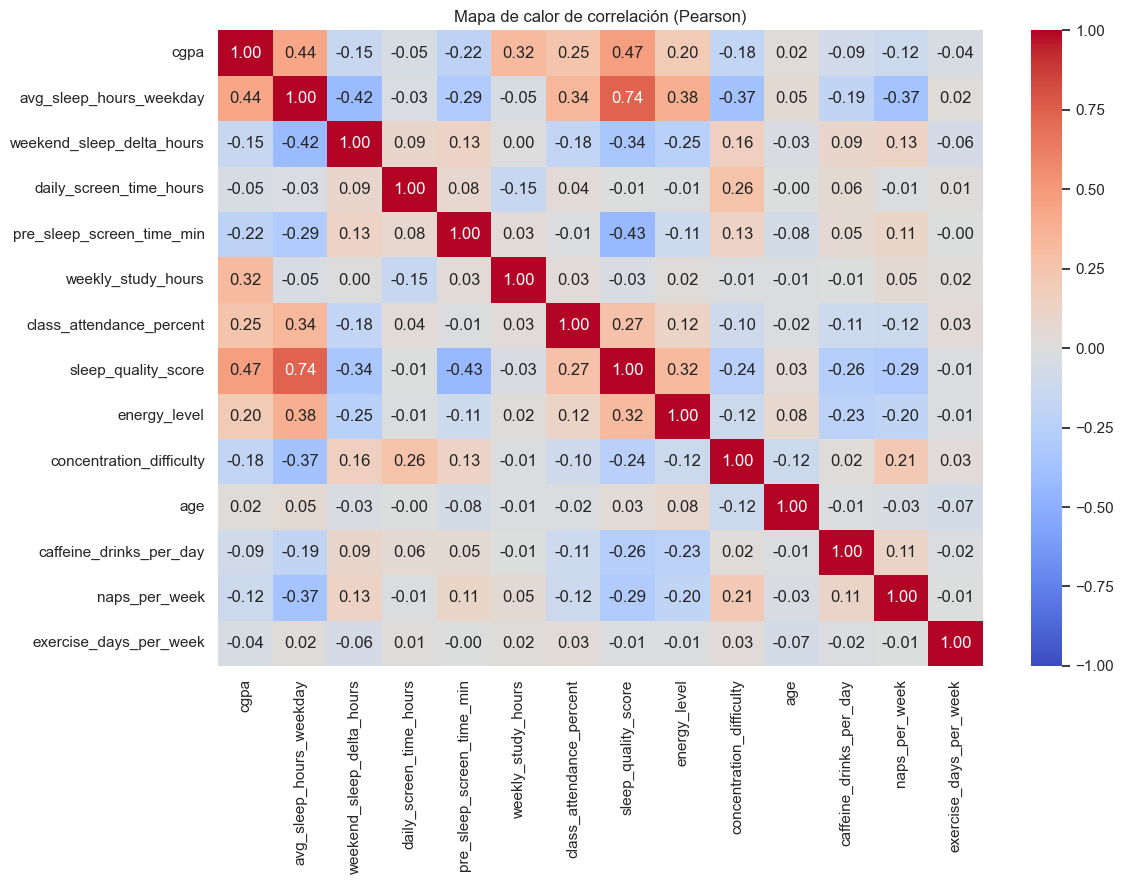

In [19]:
corr = df_clean[variables_numericas + ["age", "caffeine_drinks_per_day", "naps_per_week", "exercise_days_per_week"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Mapa de calor de correlación (Pearson)")
plt.tight_layout()
plt.show()

In [20]:
corr_con_cgpa = corr["cgpa"].drop("cgpa").sort_values(key=abs, ascending=False)
pd.DataFrame({
    "correlación con cgpa": corr_con_cgpa.round(3),
    "interpretación": corr_con_cgpa.map(interpretar_correlacion),
})

,correlación con cgpa,interpretación
sleep_quality_score,0.47,Relación lineal débil
avg_sleep_hours_weekday,0.43,Relación lineal débil
weekly_study_hours,0.32,Relación lineal débil
class_attendance_percent,0.25,Relación lineal débil
pre_sleep_screen_time_min,-0.22,No hay relación lineal
energy_level,0.20,No hay relación lineal
concentration_difficulty,-0.18,No hay relación lineal
weekend_sleep_delta_hours,-0.15,No hay relación lineal
naps_per_week,-0.12,No hay relación lineal
caffeine_drinks_per_day,-0.09,No hay relación lineal


Ninguna variable individual tiene una correlación lineal fuerte con `cgpa`: las más relacionadas son `class_attendance_percent` y `weekly_study_hours` (relación positiva débil/moderada) y `daily_screen_time_hours` junto con `pre_sleep_screen_time_min` (relación negativa débil). Esto es razonable: el rendimiento académico depende de muchos factores a la vez, y es poco probable que una sola variable lo explique por sí sola — por eso tiene sentido un modelo que combine varias.

⚠️ Importante: estas correlaciones son lineales y **no implican causalidad**. Que más horas de pantalla se asocien a menor `cgpa` no prueba que las pantallas *causen* peor rendimiento — podría haber variables no observadas (por ejemplo, hábitos generales de organización del tiempo) que expliquen ambas cosas a la vez.

### 3.2 Scatterplots contra la variable a predecir (`cgpa`)

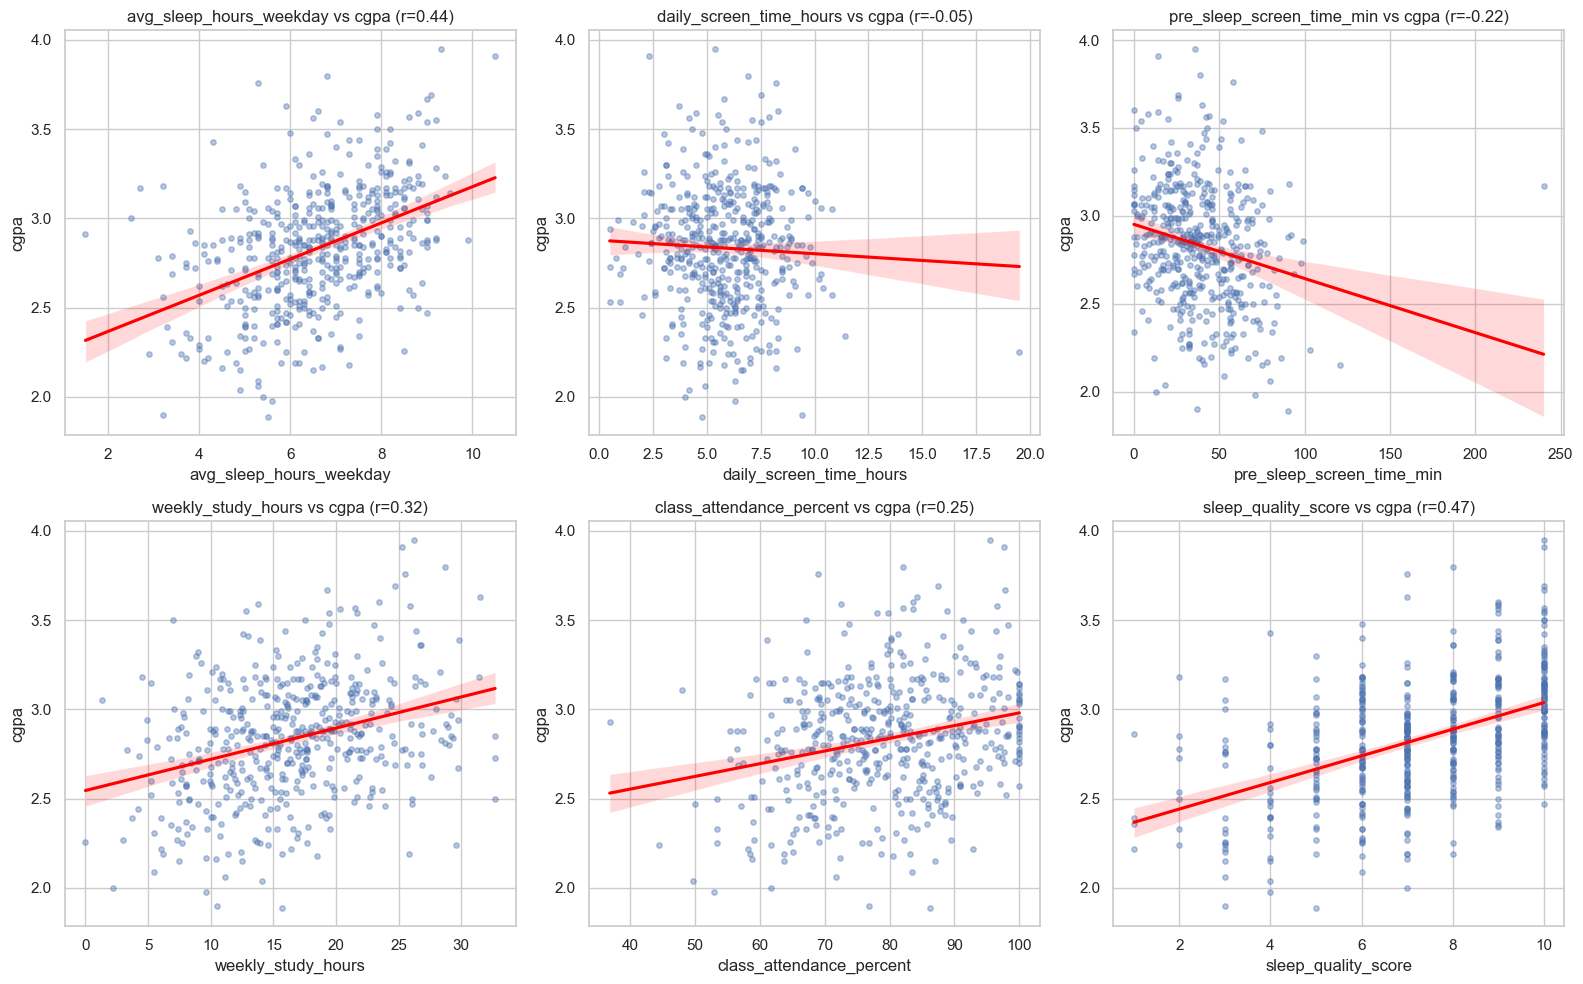

In [21]:
variables_vs_cgpa = [
    "avg_sleep_hours_weekday", "daily_screen_time_hours",
    "pre_sleep_screen_time_min", "weekly_study_hours",
    "class_attendance_percent", "sleep_quality_score",
]

plt.figure(figsize=(16, 10))
for i, col in enumerate(variables_vs_cgpa, start=1):
    plt.subplot(2, 3, i)
    sns.regplot(data=df_clean, x=col, y="cgpa", scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    r = df_clean[col].corr(df_clean["cgpa"])
    plt.title(f"{col} vs cgpa (r={r:.2f})")
plt.tight_layout()
plt.show()

Se nota una nube de puntos bastante dispersa en todos los casos (consistente con las correlaciones débiles del heatmap), pero las rectas de tendencia confirman la dirección esperada: a más `class_attendance_percent` y `weekly_study_hours`, `cgpa` tiende a subir levemente; a más `daily_screen_time_hours` y `pre_sleep_screen_time_min`, tiende a bajar levemente. `avg_sleep_hours_weekday` y `sleep_quality_score` muestran una tendencia positiva todavía más tenue.

### 3.3 `cgpa` según variables categóricas

Además de las numéricas, vemos si `cgpa` cambia según algunas categorías relevantes del dataset.

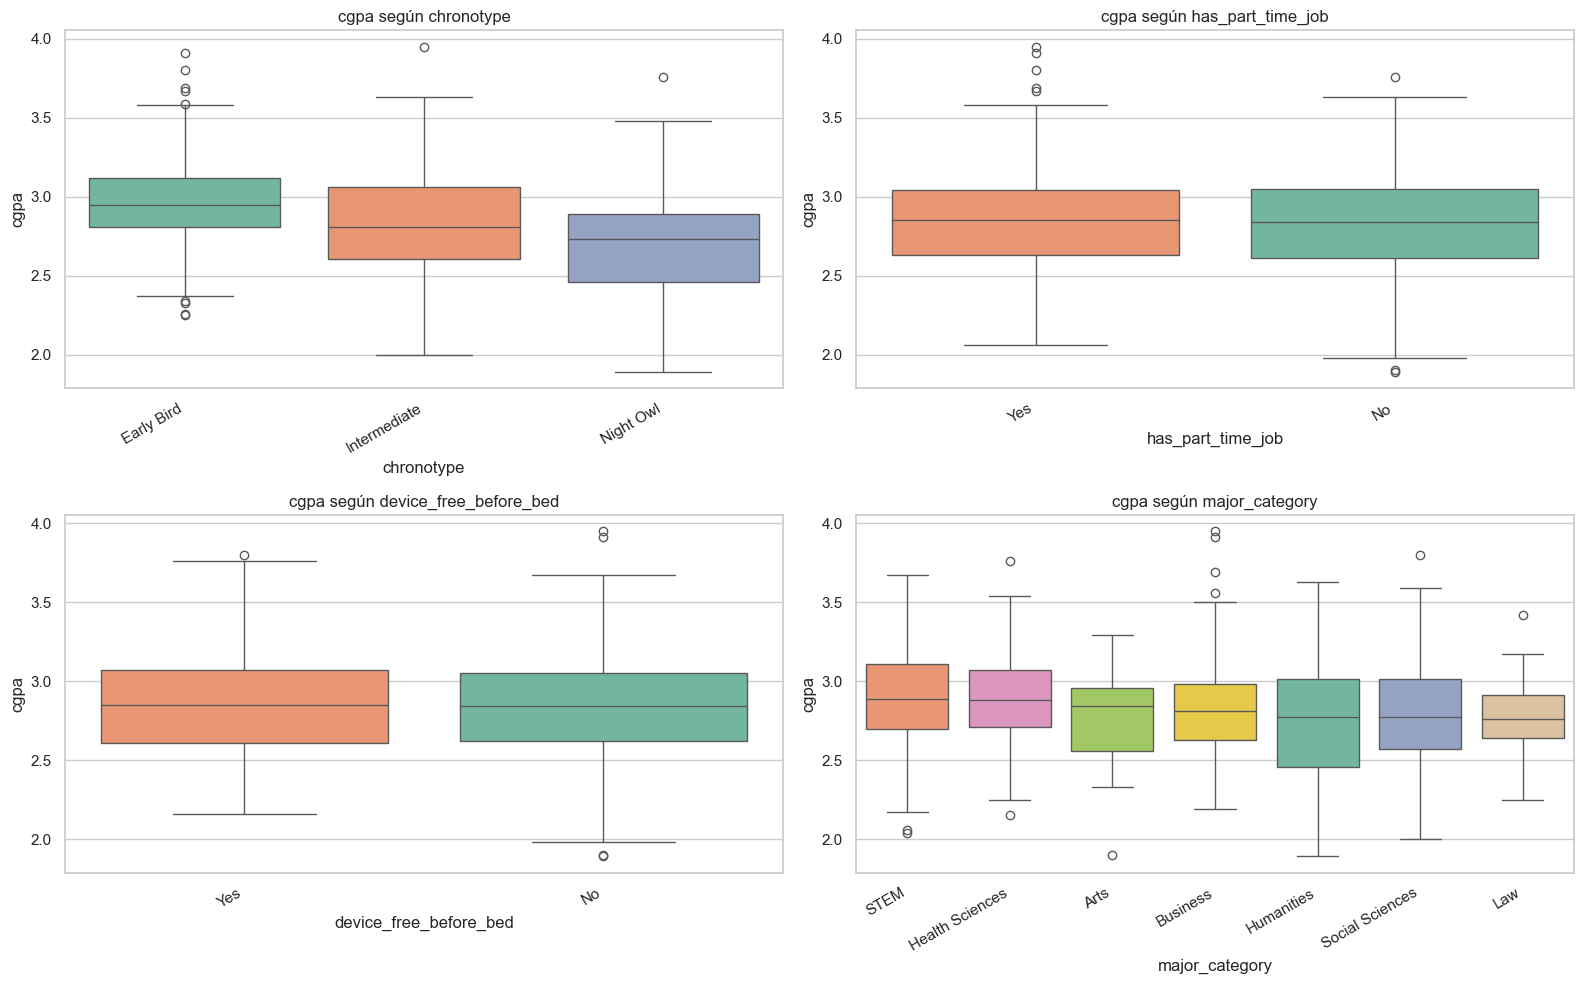

In [22]:
variables_cat_vs_cgpa = ["chronotype", "has_part_time_job", "device_free_before_bed", "major_category"]

plt.figure(figsize=(16, 10))
for i, col in enumerate(variables_cat_vs_cgpa, start=1):
    plt.subplot(2, 2, i)
    orden = df_clean.groupby(col)["cgpa"].median().sort_values(ascending=False).index
    sns.boxplot(data=df_clean, x=col, y="cgpa", order=orden, hue=col, palette="Set2", legend=False)
    plt.title(f"cgpa según {col}")
    plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [23]:
print("Mediana de cgpa por chronotype:")
print(df_clean.groupby("chronotype")["cgpa"].median().sort_values(ascending=False))
print()
print("n por chronotype:")
print(df_clean["chronotype"].value_counts())

Mediana de cgpa por chronotype:
chronotype
Early Bird     2.95
Intermediate   2.81
Night Owl      2.73
Name: cgpa, dtype: float64

n por chronotype:
chronotype
Intermediate    199
Early Bird      149
Night Owl       145
Name: count, dtype: int64


Las medianas de `cgpa` son parecidas entre `chronotype`s y entre quienes tienen o no trabajo part-time: las cajas se superponen bastante, así que a simple vista ninguna categoría se destaca con un `cgpa` claramente mayor o menor. `major_category` muestra algo más de variación entre carreras, pero varias de esas categorías tienen pocos casos (ver conteos de la sección 2.2), así que cualquier diferencia hay que mirarla con cautela: con muestras chicas, una mediana se puede mover mucho con uno o dos estudiantes más.

### 3.4 Agregación + bivariado: screen time y sueño por cronotipo

Como adelanto a la sección de agregaciones (que va a desarrollar el resto del equipo), vemos si el tiempo de pantalla y las horas de sueño varían según el cronotipo — tiene sentido pensar que un `Night Owl` use más pantalla antes de dormir que un `Early Bird`.

In [24]:
agg_chronotype = df_clean.groupby("chronotype").agg(
    sueño_promedio=("avg_sleep_hours_weekday", "mean"),
    screen_time_promedio=("daily_screen_time_hours", "mean"),
    screen_pre_sleep_promedio=("pre_sleep_screen_time_min", "mean"),
    cgpa_promedio=("cgpa", "mean"),
    n=("cgpa", "size"),
).round(2).sort_values("screen_pre_sleep_promedio", ascending=False)
agg_chronotype

,sueño_promedio,screen_time_promedio,screen_pre_sleep_promedio,cgpa_promedio,n
chronotype,,,,,
Night Owl,5.46,5.99,56.16,2.70,145
Intermediate,6.73,5.80,37.69,2.83,199
Early Bird,7.56,5.71,22.18,2.96,149


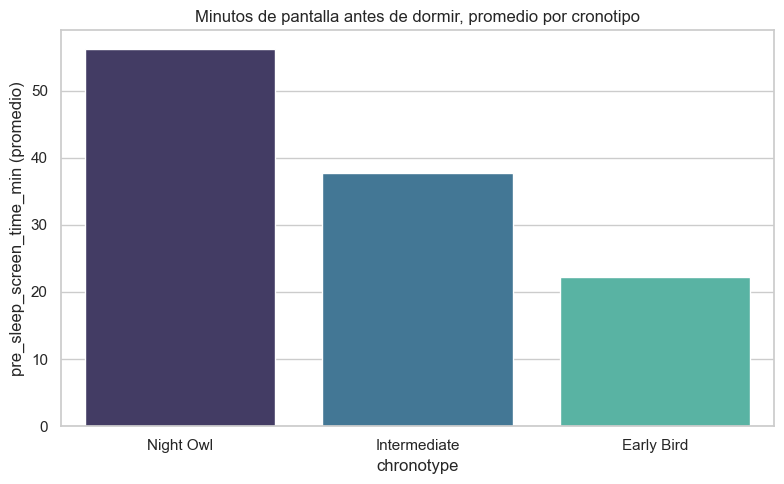

In [25]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=agg_chronotype.reset_index(), x="chronotype", y="screen_pre_sleep_promedio",
    hue="chronotype", palette="mako", legend=False,
)
plt.title("Minutos de pantalla antes de dormir, promedio por cronotipo")
plt.ylabel("pre_sleep_screen_time_min (promedio)")
plt.tight_layout()
plt.show()

Como era de esperar, los `Night Owl` son quienes más minutos de pantalla usan justo antes de dormir, seguidos por `Intermediate` y por último `Early Bird`. Las diferencias en `cgpa` promedio entre cronotipos, en cambio, son chicas (entre 2.78 y 2.88), lo que confirma lo que vimos en los boxplots de 3.3: el cronotipo por sí solo no parece ser un buen predictor de rendimiento académico.

### 3.5 🔑 Resumen del EDA bivariado

| Variable | Relación con `cgpa` | Lectura |
|---|---|---|
| `class_attendance_percent` | Positiva, débil-moderada | Más asistencia, levemente más rendimiento |
| `weekly_study_hours` | Positiva, débil | Más horas de estudio, levemente más rendimiento |
| `daily_screen_time_hours` | Negativa, débil | Más pantalla total, levemente menos rendimiento |
| `pre_sleep_screen_time_min` | Negativa, débil | Más pantalla antes de dormir, levemente menos rendimiento |
| `avg_sleep_hours_weekday` | Positiva, muy débil | Dormir más se asocia muy levemente a mejor rendimiento |
| `sleep_quality_score` | Positiva, muy débil | Misma lectura, relación tenue |
| `chronotype`, `has_part_time_job`, `device_free_before_bed` | Sin diferencias claras | Las medianas de `cgpa` se superponen entre grupos |

**Conclusión de esta etapa:** ninguna variable por sí sola explica bien el `cgpa`, pero varias apuntan en la dirección esperada (asistencia y estudio suman, pantalla resta). Esto sugiere que vale la pena probar un modelo que combine varias variables a la vez (regresión lineal múltiple o KNN regressor) en lugar de depender de una sola — que es justo lo que viene en la siguiente sección.

## 4. Agregaciones y visualizaciones adicionales

_Pendiente — a cargo del resto del equipo._

Ya dejamos un ejemplo de `groupby` + `agg` con barplot en la sección 3.4 (screen time y sueño por cronotipo) como punto de partida. Falta, como mínimo: otra agregación relevante con su barplot, y evaluar si suman visualizaciones de otras plataformas (ej. Flourish). El dataset no tiene variables de fecha, así que no corresponde una serie de tiempo.

## 5. Modelo de regresión lineal o k-NN

_Pendiente — a cargo del resto del equipo._

Definir `X` (predictoras) e `y = cgpa`, separar en train/test, comparar contra un baseline (media de train), entrenar regresión lineal y/o KNN regressor, elegir hiperparámetros por validación cruzada y evaluar con RMSE, MAE y R².

⚠️ Tener en cuenta `avg_bedtime_hour` (variable circular, no usar sin recodificar — ver sección 1.6) y escalar las predictoras si se usa KNN con más de una variable.

## 6. Conclusiones

_Pendiente — a cargo del resto del equipo._

Qué aprendimos de los datos, qué tan bien funciona el modelo, en qué se equivoca y qué le agregarían para mejorarlo.